In [ ]:
import ants
import nibabel as nib
import numpy as np
import pandas as pd
import nilearn
from nilearn import surface
import os
from brainstat.datasets import fetch_mask, fetch_template_surface
from brainspace.plotting import plot_hemispheres
import scipy.stats as stats

pial_left, pial_right = fetch_template_surface("fslr32k",join=False)
mask = fetch_mask("fslr32k")

In [2]:
# Calculate Mutual Information using ANTsPy
def mutual_information(img1, img2, bins=32):
    """Calculate mutual information between two images using ANTsPy."""
    if img1 is None or img2 is None:
        return None
    # Convert numpy arrays to ANTs images
    img1_ants = ants.from_numpy(img1.astype(np.float32))
    img2_ants = ants.from_numpy(img2.astype(np.float32))
    # Calculate mutual information directly with ANTsPy
    return ants.image_mutual_information(img1_ants, img2_ants)

In [3]:
# Generate mean and stdev maps
def mean_std_gen(L_surf,R_surf,mask):
    mean = np.hstack((
        np.mean(L_surf,axis=0),
        np.mean(R_surf,axis=0)
    ))
    mean[~mask] = np.nan
    
    std = np.hstack((
        np.std(L_surf,axis=0),
        np.std(R_surf,axis=0)
    ))
    std[~mask] = np.nan
    
    return np.vstack((mean,std))

In [4]:
# Generate cohen's D map
from scipy import stats
from statsmodels.stats.multitest import multipletests

def cohenD_gen(L_surf,R_surf,HC_L_surf,HC_R_surf,mask):
    HC_mean = np.hstack((
        np.mean(HC_L_surf,axis=0),
        np.mean(HC_R_surf,axis=0)
    ))
    
    HC_std = np.hstack((
        np.std(HC_L_surf,axis=0),
        np.std(HC_R_surf,axis=0)
    ))
    
    n1 = HC_mean.shape[0]
    
    test_mean = np.hstack((
        np.mean(L_surf,axis=0),
        np.mean(R_surf,axis=0)
    ))
    test_std = np.hstack((
        np.std(L_surf,axis=0),
        np.std(R_surf,axis=0)
    ))
    n2 = test_mean.shape[0]
    
    pooled_std = np.sqrt(((n1 - 1) * HC_std + (n2 - 1) * test_std) / (n1 + n2 - 2))
    
    cohens_d = (test_mean - HC_mean) / pooled_std

    # tstats,pvals = stats.ttest_ind(np.hstack((L_surf,R_surf)),
    #                                 np.hstack((HC_L_surf,HC_R_surf)),
    #                                 axis=0,
    #                             equal_var=False)  
    
    # # Apply False Discovery Rate (FDR) correction at a 5% significance level
    # reject_null, corrected_pvals, _, _ = multipletests(pvals, 
    #                                                     alpha=0.05, 
    #                                                     method='fdr_bh')                        
    
    # to_return = np.vstack((tstats,corrected_pvals,cohens_d))
    
    to_return = cohens_d
    to_return[~mask] = np.nan
    
    return to_return

# AV45

In [23]:
T_AV45 = pd.read_csv("/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45/AV45_shortlist_demographics.csv")
BIDS_AV45 = '/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45'

mi_values = []

for subj in T_AV45['Subject_short']:
    img1 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-AV45_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)
    
T_AV45['Mutual_Information'] = mi_values



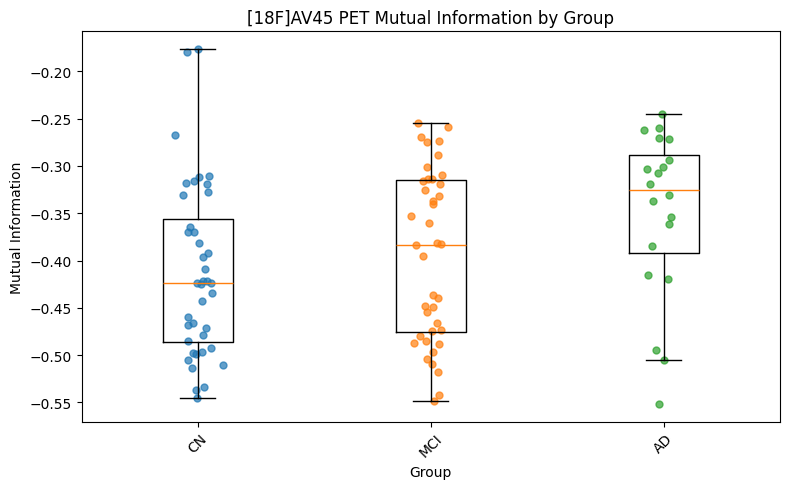

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_AV45[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["CN", "MCI", "AD"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups, showfliers=False)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("[18F]AV45 PET Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#ANOVA 

# Unpack the 'Mutual_information' values grouped by the 'Group' column
grouped_data = [group['Mutual_Information'].values for name, group in T_AV45.groupby('Group')]

# Perform the one-way ANOVA
f_statistic, p_value = stats.f_oneway(*grouped_data)

print(f"F-Statistic: {f_statistic}")
print(f"p-value: {p_value}")

F-Statistic: 3.267211703171906
p-value: 0.04234652769776393


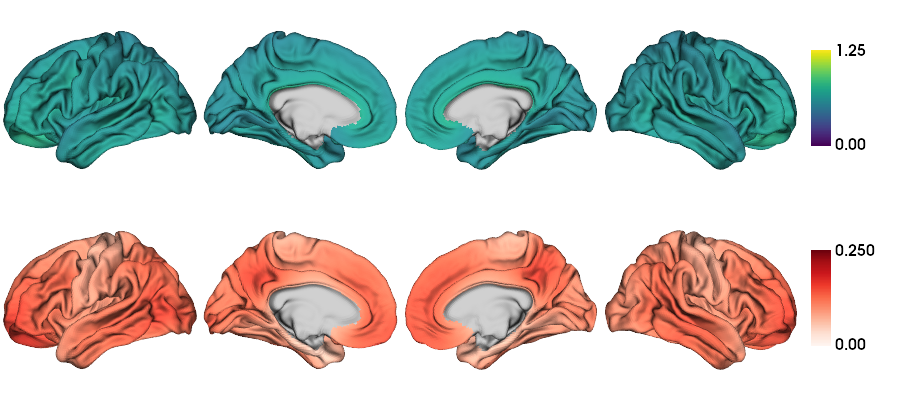

In [63]:
surf_L = []
surf_R = []
group = "CN"

MICA_PET_dir = f"{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_AV45[T_AV45["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
HC_L_surf = surf_L
HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,1.25),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["viridis","Reds"])


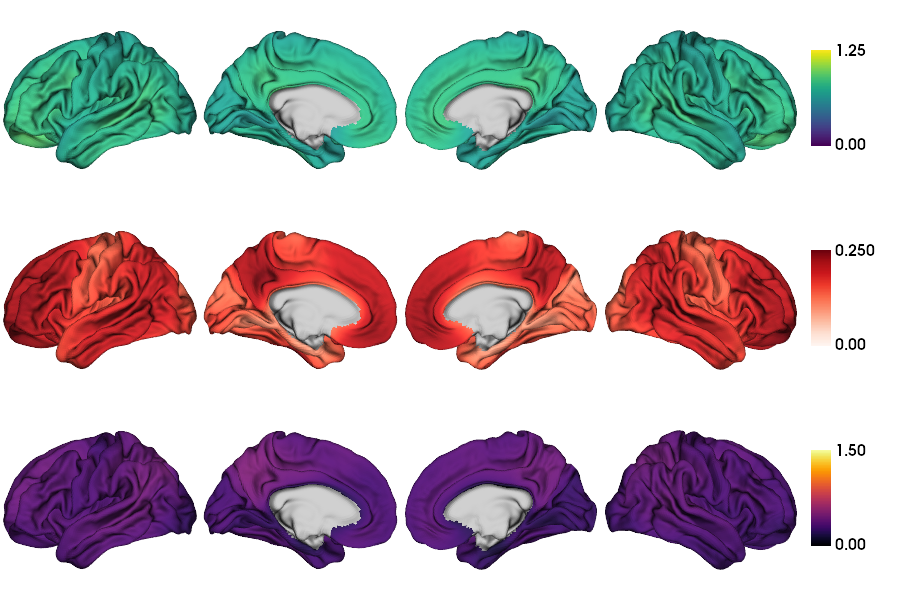

In [72]:
surf_L = []
surf_R = []
group = "MCI"

MICA_PET_dir = f"{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_AV45[T_AV45["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,1.25),(0,0.25),(0,1.5)],
                cmap=["viridis","Reds","inferno"])


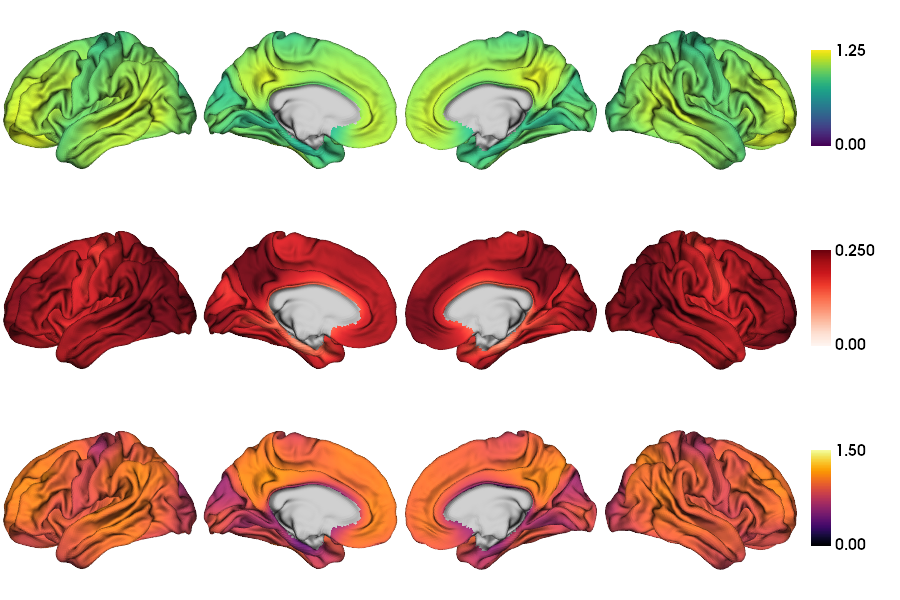

In [71]:
surf_L = []
surf_R = []
group = "AD"

MICA_PET_dir = f"{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_AV45[T_AV45["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-IY_ref-composite_smooth-10mm_trc-AV45_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,1.25),(0,0.25),(0,1.5)],
                cmap=["viridis","Reds","inferno"])

# MK6240


In [26]:
T_MK6240 = pd.read_csv("/host/verges/tank/data/jack/MK6240/BIDS_test_MK6240_ADNI4/MK6240_shortlist_demographics.csv")
T_MK6240 = T_MK6240[T_MK6240['Subject_short'] != "016S10441"]  # Exclude subject 016S10441
BIDS_MK6240 = '/host/verges/tank/data/jack/MK6240/BIDS_test_MK6240_ADNI4'

mi_values = []

for subj in T_MK6240['Subject_short']:
    img1 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-MK6240_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_MK6240['Mutual_Information'] = mi_values


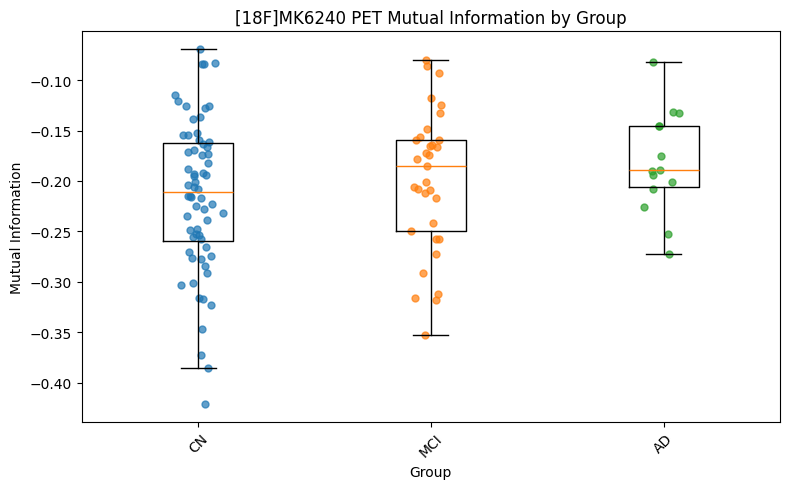

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_MK6240[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["CN", "MCI", "AD"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups, showfliers=False)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("[18F]MK6240 PET Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
#ANOVA 

# Unpack the 'Mutual_information' values grouped by the 'Group' column
grouped_data = [group['Mutual_Information'].values for name, group in T_MK6240.groupby('Group')]

# Perform the one-way ANOVA
f_statistic, p_value = stats.f_oneway(*grouped_data)

print(f"F-Statistic: {f_statistic}")
print(f"p-value: {p_value}")

F-Statistic: 1.4441146080210796
p-value: 0.24047425679732373


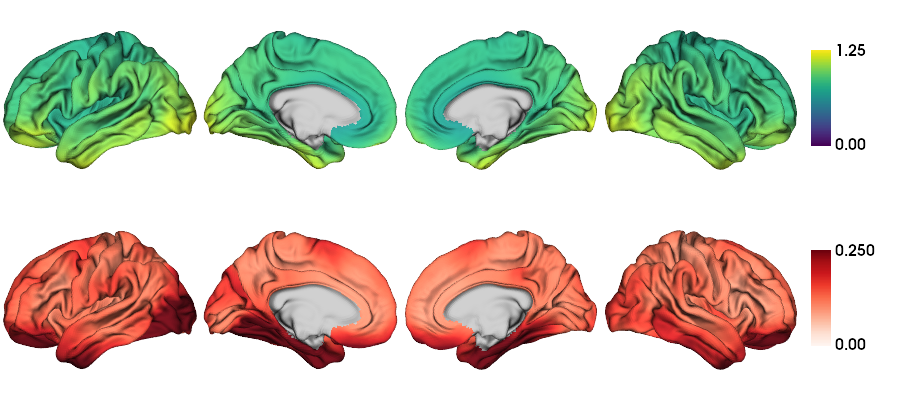

In [79]:
surf_L = []
surf_R = []
group = "CN"
trc = "MK6240"
pvc = "IY"
ref = "cerebellarGM"

MICA_PET_dir = f"{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_MK6240[T_MK6240["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
HC_L_surf = surf_L
HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,1.25),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["viridis","Reds"])

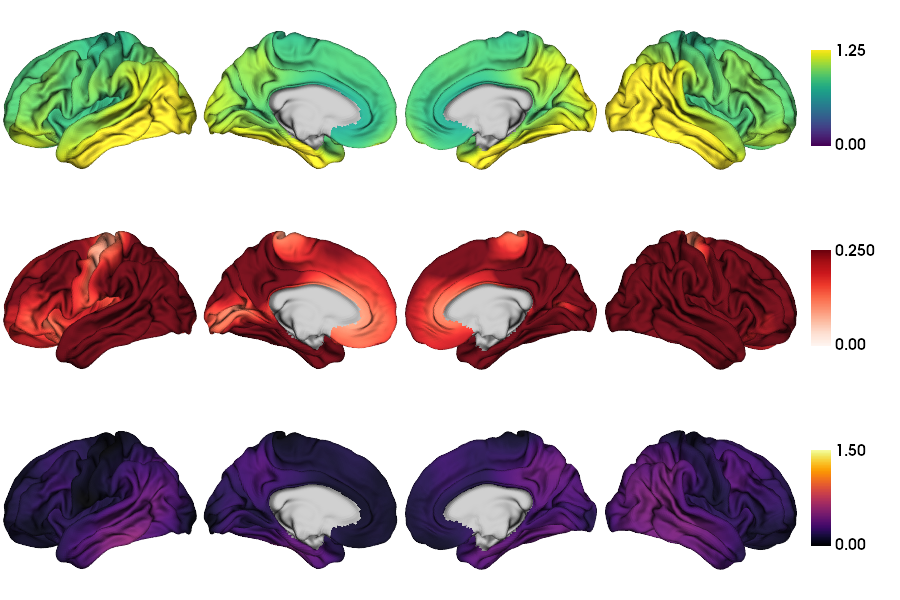

In [80]:
surf_L = []
surf_R = []
group = "MCI"
trc = "MK6240"
pvc = "IY"
ref = "cerebellarGM"

MICA_PET_dir = f"{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_MK6240[T_MK6240["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,1.25),(0,0.25),(0,1.5)],
                cmap=["viridis","Reds","inferno"])

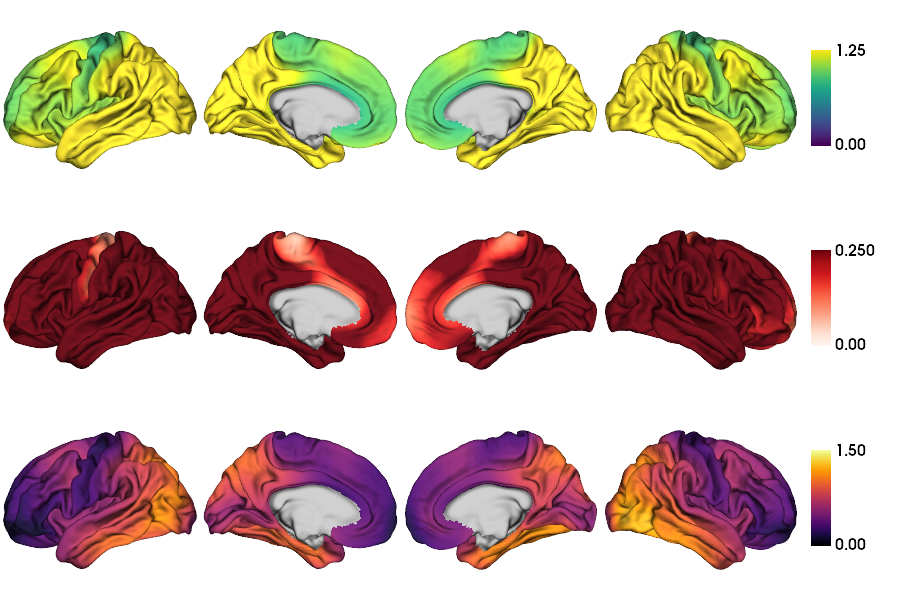

In [81]:
surf_L = []
surf_R = []
group = "AD"
trc = "MK6240"
pvc = "IY"
ref = "cerebellarGM"

MICA_PET_dir = f"{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5"

for subj in T_MK6240[T_MK6240["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,1.25),(0,0.25),(0,1.5)],
                cmap=["viridis","Reds","inferno"])

# FDG

In [10]:
T_FDG_ADNI = pd.read_csv("/host/verges/tank/data/jack/FDG/BIDS_ADNI1_FDG/FDG_shortlist_demographics.csv")
BIDS_FDG_ADNI = '/host/verges/tank/data/jack/FDG/BIDS_ADNI1_FDG'

mi_values = []

for subj in T_FDG_ADNI['Subject_short']:
    
    img1 = nib.load(f'{BIDS_FDG_ADNI}/derivatives/MICA-PET_v.alpha.0.6/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG_ADNI}/derivatives/MICA-PET_v.alpha.0.6/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_FDG_ADNI['Mutual_Information'] = mi_values

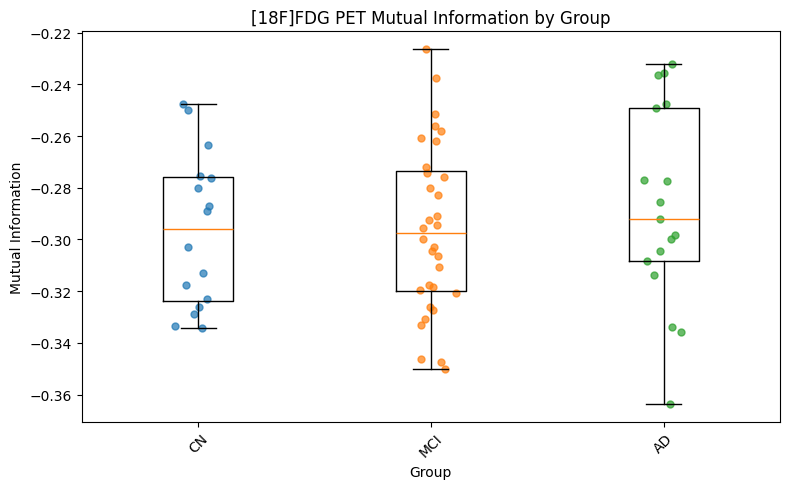

In [11]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_FDG_ADNI[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["CN", "MCI", "AD"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups, showfliers=False)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("[18F]FDG PET Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
#ANOVA 

# Unpack the 'Mutual_information' values grouped by the 'Group' column
grouped_data = [group['Mutual_Information'].values for name, group in T_FDG_ADNI.groupby('Group')]

# Perform the one-way ANOVA
f_statistic, p_value = stats.f_oneway(*grouped_data)

print(f"F-Statistic: {f_statistic}")
print(f"p-value: {p_value}")

F-Statistic: 0.41397629999230934
p-value: 0.6628301342912637


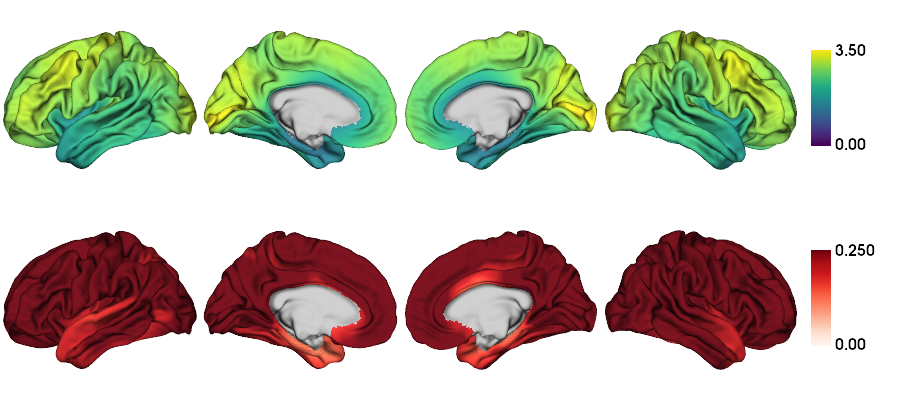

In [20]:
surf_L = []
surf_R = []
group = "CN"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_ADNI}/derivatives/MICA-PET_v.alpha.0.6"

for subj in T_FDG_ADNI[T_FDG_ADNI["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
HC_L_surf = surf_L
HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,3.5),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["viridis","Reds"])

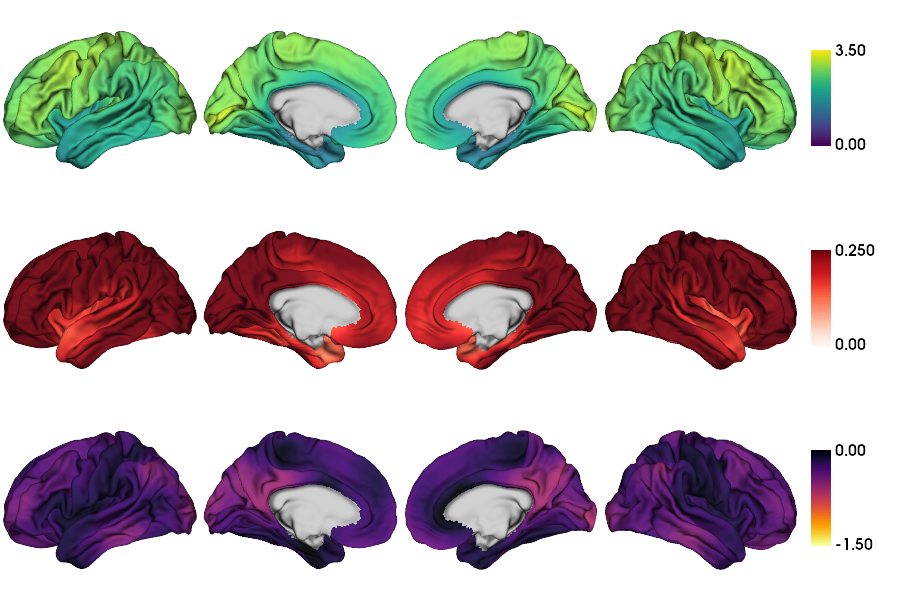

In [21]:
surf_L = []
surf_R = []
group = "MCI"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_ADNI}/derivatives/MICA-PET_v.alpha.0.6"

for subj in T_FDG_ADNI[T_FDG_ADNI["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,3.5),(0,0.25),(-1.5,0)],
                cmap=["viridis","Reds","inferno_r"])

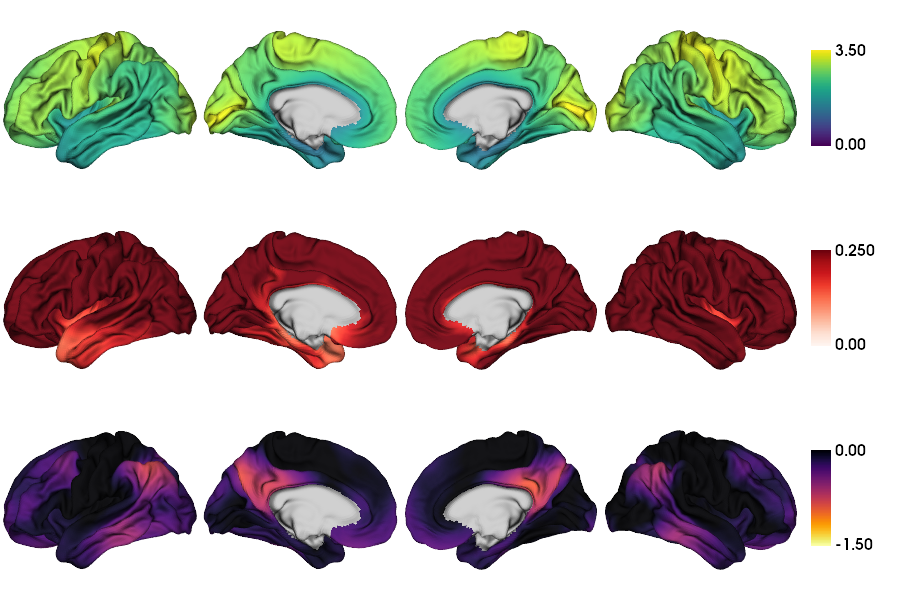

In [22]:
surf_L = []
surf_R = []
group = "AD"
trc = "FDG"
pvc = "RBV-FS"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_ADNI}/derivatives/MICA-PET_v.alpha.0.6"

for subj in T_FDG_ADNI[T_FDG_ADNI["Group"] == group].Subject_short:
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,HC_L_surf,HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,3.5),(0,0.25),(-1.5,0)],
                cmap=["viridis","Reds","inferno_r"])

In [36]:
T_FDG_BTTH = pd.read_csv("/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1/BIDS_BTTH1_demo.csv")
BIDS_FDG_BTTH = '/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1'
T_FDG_BTTH = T_FDG_BTTH[T_FDG_BTTH['ID'] != "sub-PX2401020"]  # Exclude subject PX2401020 -> recheck later


mi_values = []

for subj in T_FDG_BTTH['ID']:
    subj = subj.removeprefix("sub-")
    
    img1 = nib.load(f'{BIDS_FDG_BTTH}/rawdata/sub-{subj}/ses-pre/anat/sub-{subj}_ses-pre_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG_BTTH}/derivatives/MICA-PET_v.alpha.0.3/sub-{subj}/ses-pre/pet/sub-{subj}_ses-pre_space-T1wNative_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_FDG_BTTH['Mutual_Information'] = mi_values
T_FDG_BTTH["Group"] = "BTTH"

In [35]:
T_FDG_MNH = pd.read_csv("/host/fladgate/local_raid/jack/FDG_ML/MICs_px_FDG_jan22.csv")
BIDS_FDG_MNH = '/host/verges/tank/data/jack/FDG/BIDS_MICs_FDG'

mi_values = []

for subj in T_FDG_MNH['ID']:
    
    img1 = nib.load(f'{BIDS_FDG_MNH}/rawdata/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG_MNH}/derivatives/MICA-PET_v.alpha.0.3/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNative_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_FDG_MNH['Mutual_Information'] = mi_values
T_FDG_MNH["Group"] = "MNH"


In [37]:
T_FDG_HC = pd.read_csv('/host/verges/tank/data/mo/BIDS_CERMEP-MRXFDG/BIDS_CERMEP-MRXFDG_demo.csv', sep='\t')
BIDS_FDG_HC = '/host/verges/tank/data/mo/BIDS_CERMEP-MRXFDG'

mi_values = []

for subj in T_FDG_HC['ID']:
    subj = subj.removeprefix("sub-")
    
    img1 = nib.load(f'{BIDS_FDG_HC}/rawdata/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.3/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNative_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata() 
    mi = mutual_information(img1, img2)
    mi_values.append(mi)
    
T_FDG_HC['Mutual_Information'] = mi_values
T_FDG_HC["Group"] = "HC"

In [39]:
T_FDG_all = pd.concat([
    T_FDG_HC[['ID', 'Mutual_Information', 'Group']],
    T_FDG_BTTH[['ID', 'Mutual_Information', 'Group']],
    T_FDG_MNH[['ID', 'Mutual_Information', 'Group']]
], ignore_index=True)

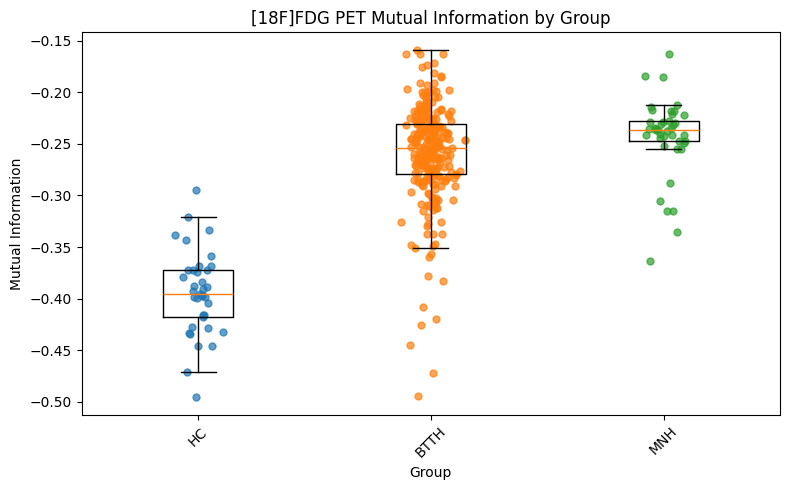

In [40]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_FDG_all[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["HC", "BTTH", "MNH"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups, showfliers=False)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("[18F]FDG PET Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

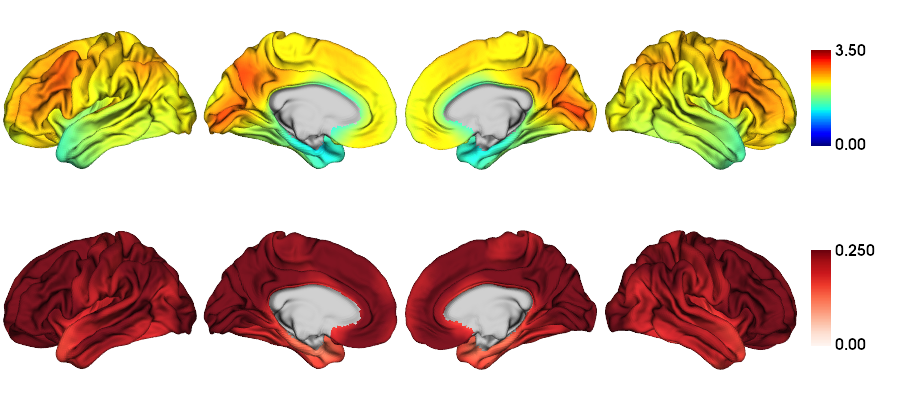

In [46]:
surf_L = []
surf_R = []
group = "HC"
trc = "FDG"
pvc = "rbv"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_HC}/derivatives/MICA-PET_v.alpha.0.3"

for subj in T_FDG_HC[T_FDG_HC["Group"] == group].ID:
    subj = subj.removeprefix("sub-")
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    surf_L.append(nilearn.surface.load_surf_data(L_file))
    surf_R.append(nilearn.surface.load_surf_data(R_file))
    
FDG_HC_L_surf = surf_L
FDG_HC_R_surf = surf_R

to_plot = mean_std_gen(surf_L,surf_R,mask)

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,color_range=[(0,3.5),(0,0.25)],size=(900,400),nan_color=(0.7, 0.7, 0.7, 1),cmap=["jet","Reds"])

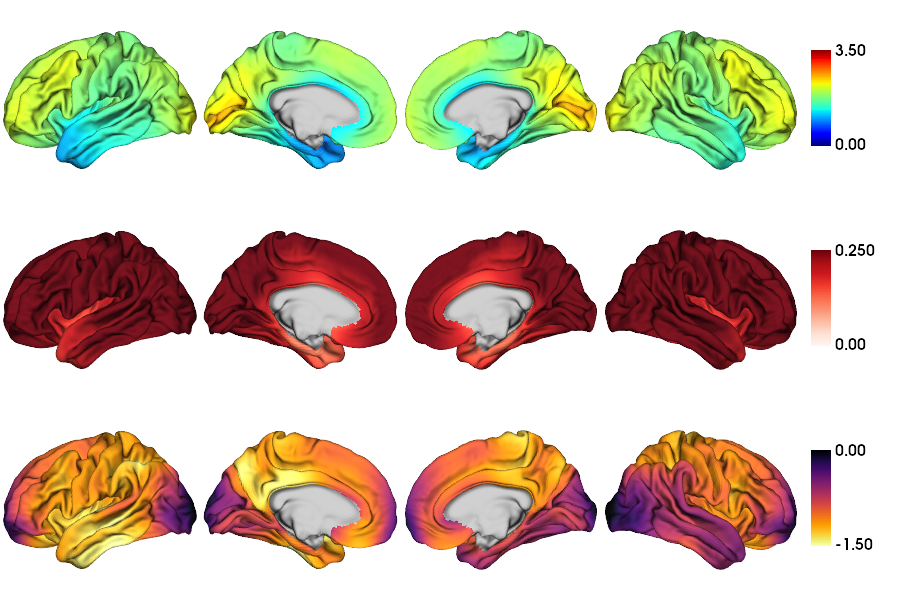

In [47]:
surf_L = []
surf_R = []
group = "BTTH"
trc = "FDG"
pvc = "rbv"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_BTTH}/derivatives/MICA-PET_v.alpha.0.3"

for subj in T_FDG_BTTH[T_FDG_BTTH["Group"] == group].ID:
    subj = subj.removeprefix('sub-')
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-pre","surf",f"sub-{subj}_ses-pre_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    if T_FDG_BTTH.loc[T_FDG_BTTH["ID"] == f'sub-{subj}', "Side"].item() == "L":
        surf_L.append(nilearn.surface.load_surf_data(L_file))
        surf_R.append(nilearn.surface.load_surf_data(R_file))
    else: 
        surf_R.append(nilearn.surface.load_surf_data(L_file))
        surf_L.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,FDG_HC_L_surf,FDG_HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,3.5),(0,0.25),(-1.50,0)],
                cmap=["jet","Reds","inferno_r"])

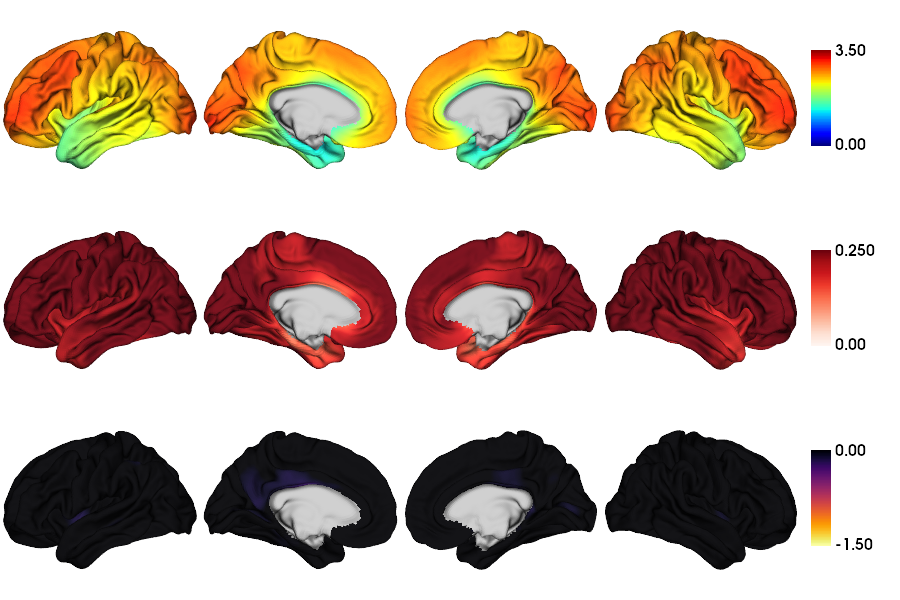

In [50]:
surf_L = []
surf_R = []
group = "MNH"
trc = "FDG"
pvc = "rbv"
ref = "pons"

MICA_PET_dir = f"{BIDS_FDG_MNH}/derivatives/MICA-PET_v.alpha.0.3"

for subj in T_FDG_MNH[T_FDG_MNH["Group"] == group].ID:
    subj = subj.removeprefix('sub-')
    L_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-L_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    R_file = os.path.join(MICA_PET_dir,f"sub-{subj}","ses-01","surf",f"sub-{subj}_ses-01_hemi-R_surf-fsLR-32k_label-midthickness_pvc-{pvc}_ref-{ref}_smooth-10mm_trc-{trc}_pet.func.gii")
    if T_FDG_MNH.loc[T_FDG_MNH["ID"] == f'{subj}', "Side"].item() == "L":
        surf_L.append(nilearn.surface.load_surf_data(L_file))
        surf_R.append(nilearn.surface.load_surf_data(R_file))
    else: 
        surf_R.append(nilearn.surface.load_surf_data(L_file))
        surf_L.append(nilearn.surface.load_surf_data(R_file))
    

to_plot = np.vstack((mean_std_gen(surf_L,surf_R,mask),cohenD_gen(surf_L,surf_R,FDG_HC_L_surf,FDG_HC_R_surf,mask)))

plot_hemispheres(pial_left, pial_right,to_plot,color_bar=True,embed_nb=True,transparent_bg=True,zoom=1.25,
                size=(900,600),
                nan_color=(0.7, 0.7, 0.7, 1),
                color_range=[(0,3.5),(0,0.25),(-1.50,0)],
                cmap=["jet","Reds","inferno_r"])